# Seção 2: Análise Exploratória de Dados (EDA)

## 2.1 Carregamento e verificação dos dados

In [ ]:
options(repr.plot.width = 10, repr.plot.height = 5)
cores <- c(negative = "#D1495B", positive = "#00798C")

In [ ]:
df <- read.csv("data/IMDB Dataset.csv", stringsAsFactors = FALSE)

dim(df)
# umm resumo do obj
str(df)

[1] 50000     2

'data.frame':	50000 obs. of  2 variables:
 $ review   : chr  "One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right"| __truncated__ "A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion "| __truncated__ "I thought this was a wonderful way to spend time on a too hot summer weekend, sitting in the air conditioned th"| __truncated__ "Basically there's a family where a little boy (Jake) thinks there's a zombie in his closet & his parents are fi"| __truncated__ ...
 $ sentiment: chr  "positive" "positive" "positive" "negative" ...


50 000 linhas e 2 colunas. ver algumas reviews:

In [ ]:
head(df)

,review,sentiment
,<chr>,<chr>
1,"One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, Irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.<br /><br />I would say the main appeal of the show is due to the fact that it goes where other shows wouldn't dare. Forget pretty pictures painted for mainstream audiences, forget charm, forget romance...OZ doesn't mess around. The first episode I ever saw struck me as so nasty it was surreal, I couldn't say I was ready for it, but as I watched more, I developed a taste for Oz, and got accustomed to the high levels of graphic violence. Not just violence, but injustice (crooked guards who'll be sold out for a nickel, inmates who'll kill on order and get away with it, well mannered, middle class inmates being turned into prison bitches due to their lack of street skills or prison experience) Watching Oz, you may become comfortable with what is uncomfortable viewing....thats if you can get in touch with your darker side.",positive
2,"A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometimes discomforting, sense of realism to the entire piece. <br /><br />The actors are extremely well chosen- Michael Sheen not only ""has got all the polari"" but he has all the voices down pat too! You can truly see the seamless editing guided by the references to Williams' diary entries, not only is it well worth the watching but it is a terrificly written and performed piece. A masterful production about one of the great master's of comedy and his life. <br /><br />The realism really comes home with the little things: the fantasy of the guard which, rather than use the traditional 'dream' techniques remains solid then disappears. It plays on our knowledge and our senses, particularly with the scenes concerning Orton and Halliwell and the sets (particularly of their flat with Halliwell's murals decorating every surface) are terribly well done.",positive
3,"I thought this was a wonderful way to spend time on a too hot summer weekend, sitting in the air conditioned theater and watching a light-hearted comedy. The plot is simplistic, but the dialogue is witty and the characters are likable (even the well bread suspected serial killer). While some may be disappointed when they realize this is not Match Point 2: Risk Addiction, I thought it was proof that Woody Allen is still fully in control of the style many of us have grown to love.<br /><br />This was the most I'd laughed at one of Woody's comedies in years (dare I say a decade?). While I've never been impressed with Scarlet Johanson, in this she managed to tone down her ""sexy"" image and jumped right into a average, but spirited young woman.<br /><br />This may not be the crown jewel of his career, but it was wittier than ""Devil Wears Prada"" and more interesting than ""Superman"" a great comedy to go see with friends.",positive
4,"Basically there's a family where a little boy (Jake) thinks there's a zombie in his closet & his parents are fighting all the time.<br /><br />This movie is slower than a soap opera... and suddenly, Jake decides to become Rambo and

aparentemente, vieram algumas coisas juntos com o site, o html(ex: `<br>`)
### Valores faltantes e balanceamento

In [ ]:
colSums(is.na(df)) #NA
sum(trimws(df$review) == "") #texto vazio ou só espaço-->da coluna review

# 'value_counts',so q do R
table(df$sentiment)
prop.table(table(df$sentiment))

review sentiment 
        0         0

[1] 0


negative positive 
   25000    25000 


negative positive 
     0.5      0.5 

nenhuma review vazia. as classes estão bem balanceadas, acurácia vai ter uma boa métrica até ne

### Duplicadas

In [ ]:
sum(duplicated(df))
sum(duplicated(df$review))#comparando so o texto

[1] 418

[1] 418

In [ ]:
# de que classe são as cópias extras?
table(df$sentiment[duplicated(df$review)])


negative positive 
     302      116 

curiosamente, a maioria das cópias (302) é de reviews negativas, acho que é bom remover as cópias. Se deixar, na hora de dividir treino e teste o modelo estaria meio q reconhecendo um texto que já viu, não generalizando


### Sujeira no texto

In [ ]:
# fração das reviews com <br />
mean(grepl("<br", df$review))

# outras tags HTML além dessa
sum(grepl("<[a-zA-Z]+[^>]*>", gsub("<br\\s*/?>", "", df$review)))

# links
sum(grepl("http|www\\.", df$review))

# ver questão de acentos? travessoes?

[1] 0.584

[1] 10

[1] 203

mais ou menos 58% das reviews têm `<br/>`. Se a gente não tirar, depois de remover a pontuação sobra a "palavra" `br`, que seria uma das mais frequentes do corpus e n significa nada
- poucas reviews têm outras tags html
- uns 200 têm links

### Variáveis pra explorar

crie algumas medidas pra explorar melhor algumas medidas de cada review

In [ ]:
df$n_palavras       <- lengths(strsplit(gsub("<[^>]+>", " ", df$review), "\\s+"))
df$tem_exclamacao   <-grepl("!",df$review)
df$tem_interrogacao <-grepl("\\?",df$review)
df$n_maiusculas     <-lengths(regmatches(df$review, gregexpr("\\b[A-Z]{3,}\\b", df$review)))  #caixa alta

head(df[, -1])

,sentiment,n_palavras,tem_exclamacao,tem_interrogacao,n_maiusculas
,<chr>,<int>,<lgl>,<lgl>,<int>
1,positive,304,FALSE,FALSE,0
2,positive,156,TRUE,FALSE,1
3,positive,164,FALSE,TRUE,0
4,negative,135,TRUE,FALSE,1
5,positive,225,FALSE,FALSE,0
6,positive,119,FALSE,FALSE,0


## 2.2 Análise univariada

### Sentimento

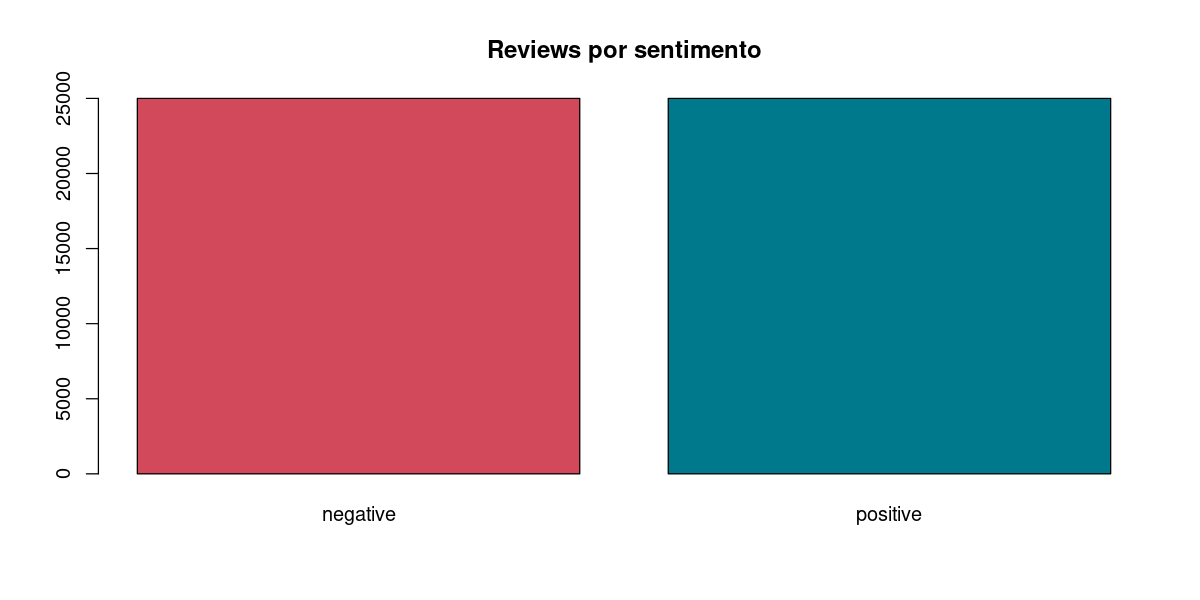

In [ ]:
barplot(table(df$sentiment), col = cores, main = "Reviews por sentimento")

### Tamanho das reviews

In [ ]:
summary(df$n_palavras)
quantile(df$n_palavras, c(0.01, 0.05, 0.95, 0.99))

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
    4.0   125.0   171.0   228.9   278.0  2459.0 

1%  5% 95% 99% 
 41  62 585 897

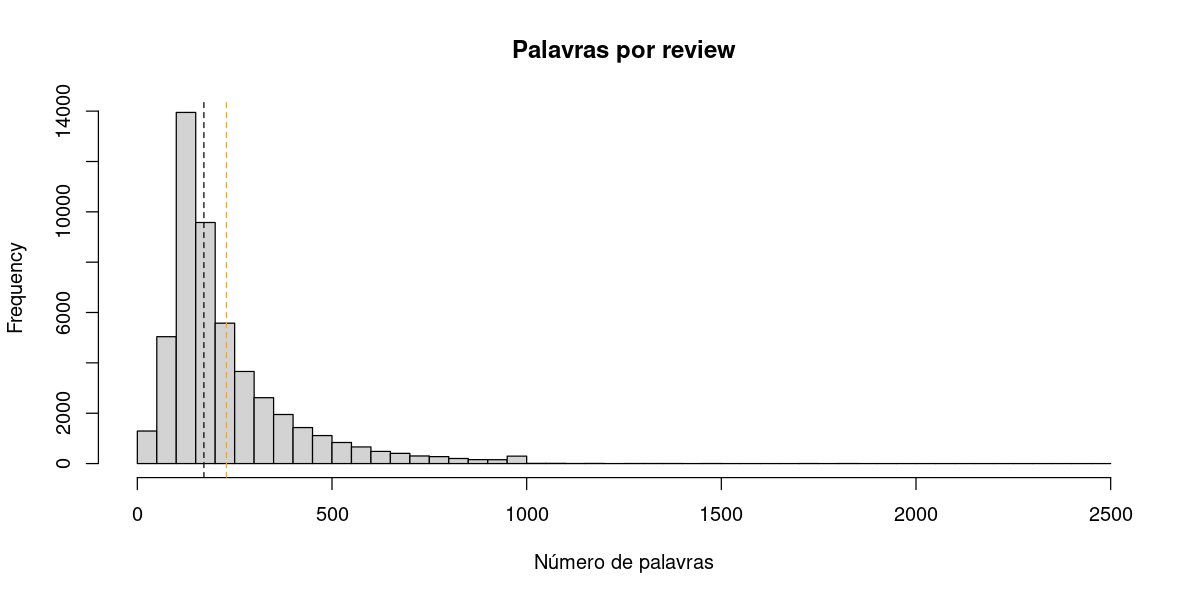

In [ ]:
hist(df$n_palavras, breaks = 80, main = "Palavras por review", xlab = "Número de palavras")
abline(v = c(median(df$n_palavras), mean(df$n_palavras)), col = c("black", "orange"), lty = 2)  #media laranja

A distribuição é bem assimétrica à direita, a maioria das reviews tem entre 125 e 280 palavras, mas existe uma cauda longa de textos enormes. por isso a média fica bem acima da mediana


### Pontuação e "gritos"

In [ ]:
mean(df$tem_exclamacao) 
mean(df$tem_interrogacao)   
table(cut(df$n_maiusculas, c(-1, 0, 1, 3, 10, Inf),
          labels = c("0", "1", "2-3", "4-10", "> 10")))

[1] 0.34698

[1] 0.29598


    0     1   2-3  4-10  > 10 
30870  8699  5783  3606  1042 

Mais ou menos 1/3 das reviews tem exclamação e uns 30% tem interrogação. A maioria não usa nenhuma palavra toda em maiúsculas. e quando usa, a maior parte se concetra em pouca qnt de maiscula

--> TO DO: tem algumas que tem nota dentro do texto?

## 2.3. Análise Bivariada e Multivariada

#### Preparação

In [ ]:
library(dplyr)
library(tidyr)
library(ggplot2)
library(tidytext)

cores <- c(negative = "#D1495B", positive = "#00798C")
df$sentiment <- factor(df$sentiment, levels = c("negative", "positive"))

# flags e faixas que ainda não foram criadas (pode pular se já existirem)
df <- df %>%
  mutate(
    tem_br       = grepl("<br", review),
    tem_html     = grepl("<[a-zA-Z]+[^>]*>", gsub("<br\\s*/?>", "", review)),
    tem_link     = grepl("http|www\\.", review),
    faixa_maiusc = cut(n_maiusculas, c(-1, 0, 1, 3, 10, Inf),
                       labels = c("0", "1", "2-3", "4-10", "> 10"))
  )

### Análise bivariada

#### variáveis numéricas x sentimento

In [ ]:
# estatísticas descritivas por grupo
df %>%
  group_by(sentiment) %>%
  summarise(
    n               = n(),
    palavras_media  = mean(n_palavras),
    palavras_med    = median(n_palavras),
    palavras_dp     = sd(n_palavras),
    maiusc_media    = mean(n_maiusculas),
    maiusc_med      = median(n_maiusculas)
  )

# Wilcoxon (distribuições assimétricas, então não usamos t-test)
wilcox.test(n_palavras ~ sentiment, data = df)
wilcox.test(n_maiusculas ~ sentiment, data = df)

# tamanho de efeito (delta de Cliff): valores > 0 indicam que reviews negativas tendem a ser maiores
cliff_delta <- function(x, g) {
  W  <- unname(wilcox.test(x ~ g)$statistic)
  n1 <- sum(g == "negative")
  n2 <- sum(g == "positive")
  2 * W / (n1 * n2) - 1
}
cliff_delta(df$n_palavras, df$sentiment)
cliff_delta(df$n_maiusculas, df$sentiment)

# boxplots (escala log, porque as distribuições são muito assimétricas)
ggplot(df, aes(sentiment, n_palavras, fill = sentiment)) +
  geom_boxplot(outlier.alpha = 0.1) +
  scale_y_log10() +
  scale_fill_manual(values = cores) +
  labs(title = "Número de palavras por sentimento (escala log)",
       x = NULL, y = "Palavras") +
  theme_minimal() +
  theme(legend.position = "none")

ggplot(df, aes(sentiment, n_maiusculas + 1, fill = sentiment)) +
  geom_boxplot(outlier.alpha = 0.1) +
  scale_y_log10() +
  scale_fill_manual(values = cores) +
  labs(title = "Número de maiúsculas por sentimento (+1, escala log)",
       x = NULL, y = "Maiúsculas + 1") +
  theme_minimal() +
  theme(legend.position = "none")

#### variáveis binárias x sentimento

In [ ]:
vars_bin <- c("tem_exclamacao", "tem_interrogacao", "tem_br", "tem_html", "tem_link")

resumo_bin <- lapply(vars_bin, function(v) {
  x    <- as.numeric(df[[v]])
  prop <- tapply(x, df$sentiment, mean)
  data.frame(
    variavel      = v,
    prop_negative = prop[["negative"]],
    prop_positive = prop[["positive"]],
    p_valor       = chisq.test(table(x, df$sentiment))$p.value
  )
}) %>% bind_rows()

resumo_bin

# gráfico de proporções por sentimento
resumo_bin %>%
  select(variavel, prop_negative, prop_positive) %>%
  pivot_longer(-variavel, names_to = "sentimento", values_to = "proporcao") %>%
  mutate(sentimento = sub("prop_", "", sentimento)) %>%
  ggplot(aes(variavel, proporcao, fill = sentimento)) +
  geom_col(position = "dodge") +
  scale_fill_manual(values = cores) +
  labs(title = "Proporção de reviews com cada característica",
       x = NULL, y = "Proporção") +
  theme_minimal()

#### faixas de maiúsculas x sentimento

In [ ]:
vars_bin <- c("tem_exclamacao", "tem_interrogacao", "tem_br", "tem_html", "tem_link")

resumo_bin <- lapply(vars_bin, function(v) {
  x    <- as.numeric(df[[v]])
  prop <- tapply(x, df$sentiment, mean)
  data.frame(
    variavel      = v,
    prop_negative = prop[["negative"]],
    prop_positive = prop[["positive"]],
    p_valor       = chisq.test(table(x, df$sentiment))$p.value
  )
}) %>% bind_rows()

resumo_bin

# gráfico de proporções por sentimento
resumo_bin %>%
  select(variavel, prop_negative, prop_positive) %>%
  pivot_longer(-variavel, names_to = "sentimento", values_to = "proporcao") %>%
  mutate(sentimento = sub("prop_", "", sentimento)) %>%
  ggplot(aes(variavel, proporcao, fill = sentimento)) +
  geom_col(position = "dodge") +
  scale_fill_manual(values = cores) +
  labs(title = "Proporção de reviews com cada característica",
       x = NULL, y = "Proporção") +
  theme_minimal()

### Análise Multivariada

#### correlação entre as features (spearman)

In [ ]:
vars_multi <- c("n_palavras", "n_maiusculas", "tem_exclamacao",
                "tem_interrogacao", "tem_br", "tem_html", "tem_link")

m_num   <- sapply(df[vars_multi], as.numeric)
m_num   <- cbind(m_num, positive = as.numeric(df$sentiment == "positive"))
cor_mat <- cor(m_num, method = "spearman")
round(cor_mat, 2)

cor_long <- as.data.frame(as.table(cor_mat))

ggplot(cor_long, aes(Var1, Var2, fill = Freq)) +
  geom_tile(color = "white") +
  geom_text(aes(label = round(Freq, 2)), size = 3) +
  scale_fill_gradient2(low = cores["negative"], mid = "white",
                       high = cores["positive"], limits = c(-1, 1)) +
  labs(title = "Correlação de Spearman entre features", x = NULL, y = NULL) +
  theme_minimal()

#### Interação entre tamanho e maiúsculas, colorido por sentimento

In [ ]:
set.seed(42)
df %>%
  slice_sample(n = 5000) %>%
  ggplot(aes(n_palavras, n_maiusculas + 1, color = sentiment)) +
  geom_point(alpha = 0.3, size = 1) +
  scale_x_log10() +
  scale_y_log10() +
  scale_color_manual(values = cores) +
  labs(title = "Palavras × maiúsculas (amostra de 5 mil reviews)",
       x = "Número de palavras (log)",
       y = "Maiúsculas + 1 (log)") +
  theme_minimal()

#### Palavras associadas a cada sentimento

In [ ]:
palavras <- df %>%
  mutate(id    = row_number(),
         texto = gsub("<[^>]+>", " ", review)) %>%   # remove tags HTML antes de tokenizar
  unnest_tokens(palavra, texto) %>%
  anti_join(stop_words, by = c("palavra" = "word")) %>%
  filter(!grepl("^[0-9]+$", palavra))

contagem <- palavras %>%
  count(sentiment, palavra) %>%
  pivot_wider(names_from = sentiment, values_from = n, values_fill = 0)

V       <- nrow(contagem)
tot_neg <- sum(contagem$negative)
tot_pos <- sum(contagem$positive)

razao <- contagem %>%
  filter(negative + positive >= 100) %>%   # evita termos raros e ruidosos
  mutate(log_odds = log((positive + 1) / (tot_pos + V)) -
                    log((negative + 1) / (tot_neg + V))) %>%
  arrange(desc(log_odds))

# top 15 para cada lado
bind_rows(
  head(razao, 15) %>% mutate(lado = "positive"),
  tail(razao, 15) %>% mutate(lado = "negative")
) %>%
  ggplot(aes(reorder(palavra, log_odds), log_odds, fill = lado)) +
  geom_col() +
  coord_flip() +
  scale_fill_manual(values = cores) +
  labs(title = "Palavras mais associadas a cada sentimento (log-odds)",
       x = NULL, y = "log-odds (positive vs negative)") +
  theme_minimal()